<a href="https://colab.research.google.com/github/fxrdhan/ML_scikit-learn_Cookbook_O-Reilly/blob/main/Chapter_08_Tree_Based_Algorithms_and_Ensemble_Methods/Chapter_08_Tree_Based_Algorithms_and_Ensemble_Methods.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Chapter 8 — Tree-Based Algorithms and Ensemble Methods

| | |
|---|---|
| **Book** | *scikit-learn Cookbook, Third Edition* — John Sukup (Packt Publishing, 2025) |
| **Library version targeted by the book** | scikit-learn 1.5 |
| **Version used to run this notebook** | scikit-learn 1.9.1 on Python 3.12 (printed by the setup cell) |
| **What this notebook contains** | reproduction of every code listing in the chapter and of the official exercise solutions, chapter and recipe summaries, theoretical deep-dives, and extra experiments |

## Chapter overview

Tree-based models need little mathematics to understand: they split the data again and again on single features, until each group is (nearly) pure. In practice they are rarely used alone. **Ensembles** combine many trees, either in parallel on resampled data (**bagging, random forests**) or one after another, each correcting its predecessors (**gradient boosting**). Chapter 8 shows how to:

* fit, read and constrain a **decision tree**;
* build a **random forest** and read its feature importances;
* fit a **gradient boosting machine (GBM)**;
* **tune** a GBM with grid search and visualize the results as a heatmap;
* **compare** bagging, boosting and **stacking** on the same data;
* practise with three exercises on the Wine, Breast Cancer and Digits datasets.

### Recipes in this chapter

| # | Recipe | Code in the book | What this notebook adds |
|---|---|---|---|
| 1 | Introduction to decision trees | Yes, 2 listings | Gini impurity and the first split computed by hand, the depth of the tree versus training and test accuracy |
| 2 | Random forests and bagging | Yes, 2 listings | The forest versus its own 100 trees, the out-of-bag estimate, impurity versus permutation importance, decision regions |
| 3 | Gradient boosting machines | Yes, 1 listing | Test accuracy after each of the 1,000 boosting stages, early stopping |
| 4 | Hyperparameter tuning for trees and ensembles | Yes, 2 listings | Twenty tied candidates, what the heatmap averages over, a randomized search done right |
| 5 | Comparing ensemble methods | Yes, 2 listings | Seven tree methods on three datasets with repeated cross-validation |
| 6 | Practical exercises with tree-based models | Official solutions | A forest on the exercise 1 data, why gradient boosting on Digits fits 1,000 trees |

### How to read this notebook

Every recipe has the same structure:

1. **Summary** — what the book says, condensed.
2. **Theory** — the ideas behind it: math, algorithms and design reasoning.
3. **Book code** — the listing reproduced from the book (page numbers refer to the printed edition), followed by an **output analysis**.
4. **Extra** — experiments written for this notebook to make the theory concrete. They are *not* part of the book.

Every code cell starts with a label comment: `# BOOK CODE` for a listing reproduced from the book, `# EXTRA` for code written for this notebook.

---
## 0. Setup

Every dataset in this chapter ships with scikit-learn (`load_iris`, `load_wine`, `load_breast_cancer`, `load_digits`), so the notebook runs offline. The book's tuning recipe uses **seaborn** for its heatmap. The setup cell prints the library versions, fixes a global seed (every listing also sets `random_state=2024`), and defines the plotting style of the extra figures. The full notebook runs in about three minutes, most of it in the repeated cross-validation of recipe 5.

In [1]:
import platform

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import seaborn
import sklearn

print(f"Python       : {platform.python_version()}")
print(f"scikit-learn : {sklearn.__version__}")
print(f"NumPy        : {np.__version__}")
print(f"SciPy        : {scipy.__version__}")
print(f"pandas       : {pd.__version__}")
print(f"Matplotlib   : {matplotlib.__version__}")
print(f"seaborn      : {seaborn.__version__}")

sk_version = tuple(int(part) for part in sklearn.__version__.split(".")[:2])
assert sk_version >= (1, 5), "This notebook needs scikit-learn >= 1.5 -> pip install -U scikit-learn"

np.random.seed(0)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)

# A quiet, colour-blind-safe style used by the extra figures in this notebook
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a"]  # blue, orange, aqua (checked for colour-vision deficiency)
INK, INK_SOFT, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.8, "grid.linestyle": "-",
    "axes.titlecolor": INK, "axes.titlesize": 11.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": INK_SOFT, "axes.labelsize": 10,
    "xtick.color": AXIS, "ytick.color": AXIS, "xtick.labelcolor": INK_SOFT, "ytick.labelcolor": INK_SOFT,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "lines.linewidth": 2, "legend.frameon": False, "legend.labelcolor": INK_SOFT,
    "figure.dpi": 110, "font.size": 10,
})

Python       : 3.12.3
scikit-learn : 1.9.1
NumPy        : 2.5.3
SciPy        : 1.18.1
pandas       : 3.0.6
Matplotlib   : 3.11.2
seaborn      : 0.13.2


---
## 1. Introduction to decision trees

### Summary

* Decision trees split the data recursively on feature values into a tree of **nodes** and **branches**:
  * each internal node is a decision on one feature;
  * each leaf gives a prediction.
* They are interpretable, handle numerical and categorical data, and "can often outperform more complex models".
* **Getting ready** — the Iris data, split 70/30 with `random_state=2024`.
* **How to do it** — `DecisionTreeClassifier(random_state=2024)` with default parameters and a styled classification report (Figure 8.1): it "performs generally well".
* **How it works:**
  * Each split tries to make the subgroups more homogeneous, measured by **Gini impurity** (the default) or **entropy**.
  * `plot_tree` draws the fitted tree (Figure 8.2). The book explains the boxes: the split rule, Gini, samples, value and class. It reads the root split `petal width (cm) <= 0.8` and a depth of four.
* **There's more** — the parameters that control complexity and overfitting: `max_depth`, `min_samples_split`, `min_samples_leaf`, `max_features` and `min_impurity_decrease`.

### Theory: impurity, greedy splitting and overfitting

**Impurity.** For a node whose samples have class proportions $p_1, \dots, p_K$:

$$
\text{Gini} = 1 - \sum_{k=1}^{K} p_k^2, \qquad \text{entropy} = -\sum_{k=1}^{K} p_k \log_2 p_k .
$$

Both are 0 for a pure node and largest when the classes are equally mixed. For Gini, that maximum is $1 - 1/K$: 0.5 for two classes, 0.667 for three, and never 1.0, as the book's description of the tree plot suggests. Gini is the probability that two samples drawn at random from the node belong to different classes.

**Greedy splitting (CART).** At each node the algorithm tries every feature $j$ and every threshold $t$ (midpoints between sorted values), and keeps the split that maximizes the **impurity decrease**:

$$
\Delta = I(\text{node}) - \frac{n_\text{left}}{n}\, I(\text{left}) - \frac{n_\text{right}}{n}\, I(\text{right}) .
$$

It then recurses on both children. The search is greedy: the best split now, not the best tree overall. Finding the optimal tree is NP-hard.

**Prediction and boundaries.** A leaf predicts its majority class, and `predict_proba` returns its class proportions. Every split is a threshold on one feature, so the decision regions are axis-aligned rectangles.

**Overfitting.** Grown to the end (the default), a tree keeps splitting until every leaf is pure, which memorizes the training set. The parameters of *There's more* stop the growth earlier, as **pre-pruning**:

* `max_depth` limits the number of levels;
* `min_samples_split` and `min_samples_leaf` set minimum node sizes;
* `min_impurity_decrease` requires each split to pay for itself.

**Post-pruning**, the cost-complexity parameter `ccp_alpha`, grows the full tree and then removes branches whose impurity reduction is worth less than $\alpha$ per leaf.

**Instability.** A small change in the data can change an early split and therefore the whole tree. This high variance is exactly what ensembles average away (recipes 2 to 5).

In [2]:
# BOOK CODE: Introduction to decision trees -- getting ready (pp. 188-189)
# Load the libraries
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report
from sklearn.metrics import accuracy_score

# Load the Iris dataset
iris = load_iris()
X = iris.data
y = iris.target

# Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=2024)

In [3]:
# BOOK CODE: Introduction to decision trees -- how to do it (pp. 189-190)
# Instantiate the model
clf = DecisionTreeClassifier(random_state=2024)

# Fit the model to the training data
clf.fit(X_train, y_train)

# Generate predictions
y_pred = clf.predict(X_test)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)

# Create a classification report
report = classification_report(
    y_test, y_pred, output_dict=True)
report_df = pd.DataFrame(report).transpose()

# Stylize the DataFrame
styled_df = (report_df
    .style
    .background_gradient(
        cmap='Blues',
        subset=['precision', 'recall', 'f1-score']
    )
    .format({
        'precision': '{:.3f}',
        'recall': '{:.3f}',
        'f1-score': '{:.3f}',
        'support': '{:.0f}'
    })
)
styled_df

,precision,recall,f1-score,support
0,1.000,1.000,1.000,18
1,0.714,0.833,0.769,12
2,0.846,0.733,0.786,15
accuracy,0.867,0.867,0.867,1
macro avg,0.853,0.856,0.852,45
weighted avg,0.873,0.867,0.867,45


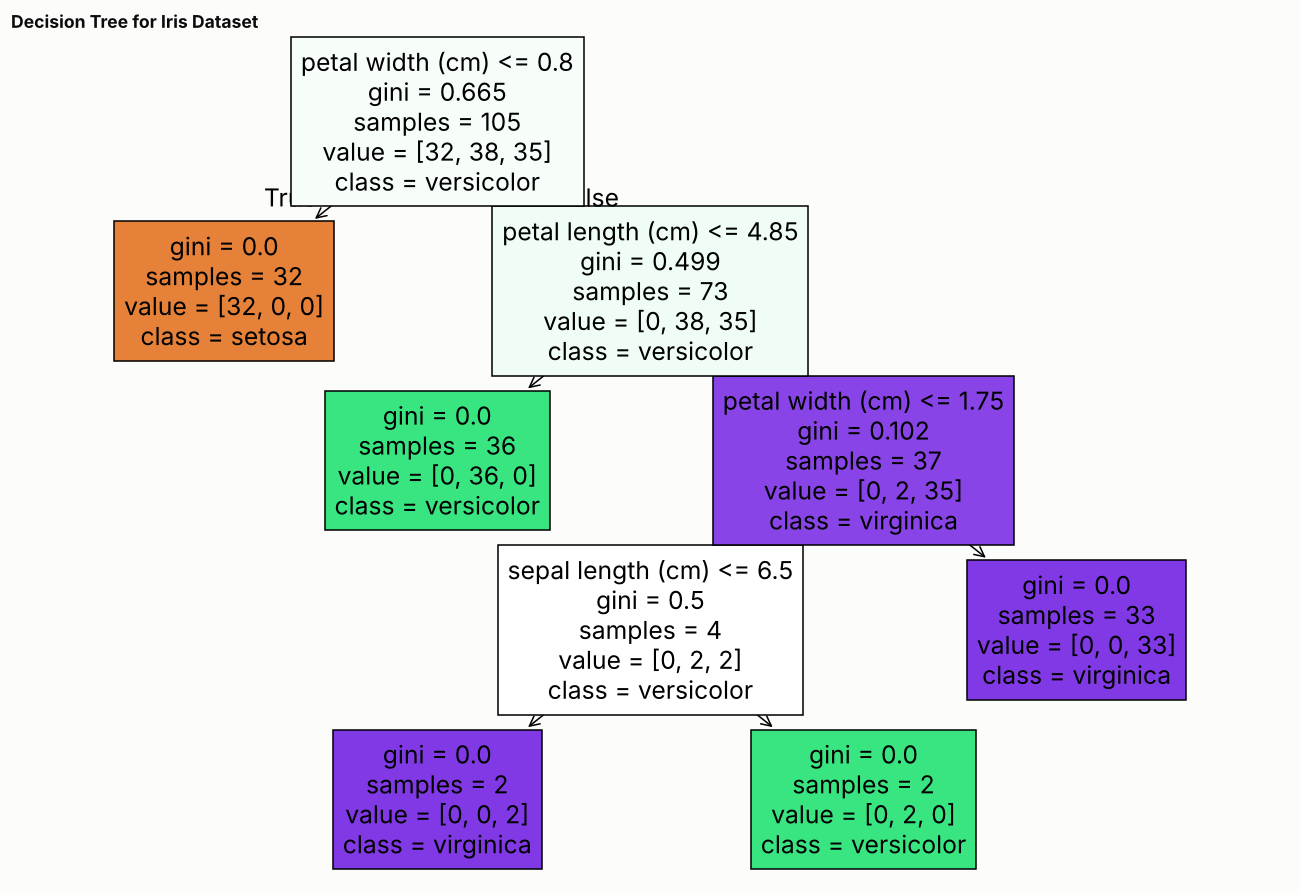

In [4]:
# BOOK CODE: Introduction to decision trees -- how it works: plot the tree (p. 190)
# Load the libraries
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

# Plot the figure
plt.figure(figsize=(15,10))
plot_tree(clf, feature_names=iris.feature_names,
          class_names=iris.target_names, filled=True)
plt.title("Decision Tree for Iris Dataset")
plt.show()

**Output analysis.**

* **Accuracy 0.867** (39 of 45 test flowers), the value the book quotes in recipe 2. Setosa is perfect; 2 versicolor and 4 virginica are misclassified.
* **The tree** matches the book's reading:
  * the root splits on `petal width (cm) <= 0.8`, which sends all 32 training setosa to a pure leaf;
  * the tree is 4 levels deep and has 5 leaves;
  * every leaf is pure, so the training accuracy is 1.0. This is the overfitting that *There's more* warns about.
* **Reading the boxes.** In the book's listing (`plot_tree` without `proportion=True`), "samples" and "value" are **counts** of training flowers: 105 at the root, split 32, 38 and 35. The book's text describes them as proportions, which is what the official notebook shows, because it passes `proportion=True`.

In [5]:
# EXTRA: (a) Gini impurity and the first split, computed by hand
def gini(labels):
    p = np.bincount(labels, minlength=3) / len(labels)
    return 1 - np.sum(p ** 2)

left = X_train[:, 3] <= 0.8                      # the root split chosen by the tree
gini_root, gini_left, gini_right = gini(y_train), gini(y_train[left]), gini(y_train[~left])
decrease = gini_root - left.mean() * gini_left - (~left).mean() * gini_right
print(f"Gini at the root   : {gini_root:.4f}   (the maximum for 3 classes is 1 - 1/3 = {1 - 1/3:.4f})")
print(f"left child  (n={left.sum():3d}): Gini {gini_left:.4f}")
print(f"right child (n={(~left).sum():3d}): Gini {gini_right:.4f}")
print(f"weighted impurity decrease: {decrease:.4f}")
print(f"scikit-learn's stored root impurity: {clf.tree_.impurity[0]:.4f}, "
      f"Gini importance of petal width: {clf.feature_importances_[3]:.3f}")

Gini at the root   : 0.6650   (the maximum for 3 classes is 1 - 1/3 = 0.6667)
left child  (n= 32): Gini 0.0000
right child (n= 73): Gini 0.4992
weighted impurity decrease: 0.3180
scikit-learn's stored root impurity: 0.6650, Gini importance of petal width: 0.504


In [6]:
# EXTRA: (b) How deep should the tree be? Training, cross-validation and test accuracy by max_depth
from sklearn.model_selection import StratifiedKFold, cross_val_score

rows = []
for depth in [1, 2, 3, 4, None]:
    tree = DecisionTreeClassifier(max_depth=depth, random_state=2024)
    cv_accuracy = cross_val_score(tree, X_train, y_train, cv=StratifiedKFold(5, shuffle=True, random_state=0)).mean()
    tree.fit(X_train, y_train)
    rows.append({"max_depth": "None (default)" if depth is None else depth, "leaves": tree.get_n_leaves(),
                 "train accuracy": round(tree.score(X_train, y_train), 3), "CV accuracy": round(cv_accuracy, 3),
                 "test accuracy": round(tree.score(X_test, y_test), 3)})
print(pd.DataFrame(rows).to_string(index=False))

     max_depth  leaves  train accuracy  CV accuracy  test accuracy
             1       2           0.667        0.657          0.667
             2       3           0.981        0.971          0.889
             3       4           0.981        0.952          0.889
             4       5           1.000        0.981          0.867
None (default)       5           1.000        0.981          0.867


**Output analysis.**

* **(a)** The root holds 32 setosa, 38 versicolor and 35 virginica, so its Gini is **0.665**, close to the three-class maximum of 0.667, not 1.0.
  * The split `petal width <= 0.8` produces a pure left child (Gini 0) and a right child with Gini 0.499, two nearly equal classes.
  * The weighted decrease, **0.318**, is the largest that any feature and threshold can achieve, which is why the tree chose it. The tree stores the same root impurity.
* **(b) Depth:**
  * One split (depth 1) can only separate setosa (0.67).
  * **Two levels (3 leaves)** already reach 0.981 training accuracy and score best on the test set (0.889).
  * The fully grown tree (depth 4, 5 leaves) adds two more leaves to fit the last training flowers. It reaches 1.000 on the training set but loses one test flower. Its cross-validation score (0.981) is as high as any, so on 105 flowers the extra depth is neither clearly harmful nor useful.
  * This is the trade-off that `max_depth` controls.

---
## 2. Random forests and bagging

### Summary

* Single trees overfit, so real applications use them in ensembles. **Random forests** combine many trees through **bootstrap aggregating (bagging)**: each tree is trained on a sample drawn with replacement, and the trees vote (or average).
* **Getting ready** — the Iris data and split of recipe 1.
* **How to do it** — `RandomForestClassifier(n_estimators=100, random_state=2024)`. The accuracy improves from the single tree's **0.867** to **0.911** (Figure 8.3).
* **How it works:**
  * besides the bootstrap samples, each split considers only a random subset of the features, which adds diversity;
  * this reduces variance and improves generalization;
  * a bar chart of `feature_importances_` (Figure 8.4) shows that petal length and petal width matter most. Forests are sometimes used only for feature selection.
* **There's more** — tune `max_features`, `max_depth` and `n_estimators`; bagging works for any model with `BaggingClassifier` and `BaggingRegressor`.

### Theory: why averaging decorrelated trees works

**Bagging.** Draw $B$ bootstrap samples (size $n$, with replacement), fit one deep tree on each, and average their votes or probabilities. Each bootstrap sample leaves out about $(1 - 1/n)^n \approx e^{-1} \approx 37\%$ of the data: the **out-of-bag (OOB)** samples. Predicting each training sample with the trees that did not see it gives a free validation estimate (`oob_score=True`).

**Variance of an average.** If each tree's prediction has variance $\sigma^2$ and any two trees have correlation $\rho$, the average of $B$ trees has variance

$$
\rho\, \sigma^2 + \frac{1 - \rho}{B}\, \sigma^2 .
$$

More trees remove the second term, but the first remains: correlated trees cannot be averaged away. **Random forests** lower $\rho$ by letting each split choose among a random subset of `max_features` features (default $\sqrt{p}$ for classification). Trees then cannot all use the same strong feature at the top. Bias is roughly that of a single deep tree, so the gain comes from variance.

**Feature importance.** Two common measures:

* **impurity-based** (`feature_importances_`, "mean decrease in impurity"): the total impurity decrease contributed by each feature, averaged over the trees. It is computed on the training data, favours features with many possible split points, and splits credit between correlated features.
* **permutation importance** (`sklearn.inspection.permutation_importance`): the drop in a score when one feature's values are shuffled, on held-out data. It is slower but measures what the model actually relies on for prediction.

In [7]:
# BOOK CODE: Random forests and bagging -- getting ready (p. 194)
# Load the libraries
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# Load the dataset
iris = load_iris()
X = iris.data
y = iris.target

# Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=2024)

In [8]:
# BOOK CODE: Random forests and bagging -- how to do it (pp. 194-195)
# (classification_report comes from recipe 1, as in the book)
# Instantiate the model
rf_clf = RandomForestClassifier(
    n_estimators=100, random_state=2024)

# Fit the model to the training data
rf_clf.fit(X_train, y_train)

# Generate predictions
y_pred = rf_clf.predict(X_test)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
report = classification_report(
    y_test, y_pred, output_dict=True)
report_df = pd.DataFrame(report).transpose()

# Stylize the DataFrame
styled_df = (report_df
    .style
    .background_gradient(
        cmap='Blues',
        subset=['precision', 'recall', 'f1-score']
    )
    .format({
        'precision': '{:.3f}',
        'recall': '{:.3f}',
        'f1-score': '{:.3f}',
        'support': '{:.0f}'
    })
)
styled_df

,precision,recall,f1-score,support
0,1.000,1.000,1.000,18
1,0.833,0.833,0.833,12
2,0.867,0.867,0.867,15
accuracy,0.911,0.911,0.911,1
macro avg,0.900,0.900,0.900,45
weighted avg,0.911,0.911,0.911,45


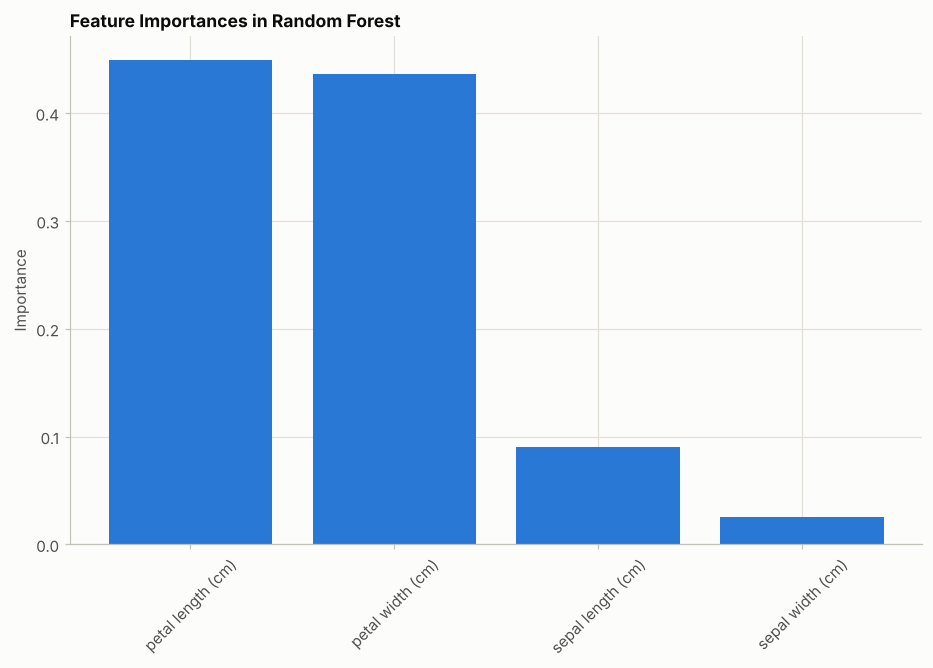

In [9]:
# BOOK CODE: Random forests and bagging -- how it works: feature importance (pp. 196-197)
# Load the libraries
import matplotlib.pyplot as plt

# Calculate feature importance
importances = rf_clf.feature_importances_
indices = np.argsort(importances)[::-1]

# Plot the feature importance
plt.figure(figsize=(10,6))
plt.title("Feature Importances in Random Forest")
plt.bar(range(X.shape[1]),
        importances[indices], align="center")
plt.xticks(range(X.shape[1]),
           [iris.feature_names[i] for i in indices],
           rotation=45)
plt.ylabel("Importance")
plt.show()

In [10]:
# EXTRA: (a) The forest versus its own trees, and the out-of-bag estimate
from sklearn.inspection import permutation_importance

tree_scores = np.array([accuracy_score(y_test, tree.predict(X_test)) for tree in rf_clf.estimators_])
print(f"the 100 individual trees on the test set: mean {tree_scores.mean():.3f}, "
      f"from {tree_scores.min():.3f} to {tree_scores.max():.3f}")
print(f"the forest (their vote)                 : {accuracy_score(y_test, y_pred):.3f}")
oob_forest = RandomForestClassifier(n_estimators=100, random_state=2024, oob_score=True).fit(X_train, y_train)
print(f"out-of-bag accuracy (training set only) : {oob_forest.oob_score_:.3f}")

wrong_tree = set(np.flatnonzero(clf.predict(X_test) != y_test))
wrong_forest = set(np.flatnonzero(y_pred != y_test))
print(f"\ntest flowers missed by the single tree: {sorted(int(i) for i in wrong_tree)}; "
      f"by the forest: {sorted(int(i) for i in wrong_forest)}")

perm = permutation_importance(rf_clf, X_test, y_test, n_repeats=30, random_state=0)
print("\n" + pd.DataFrame({"impurity importance (training)": rf_clf.feature_importances_.round(3),
                           "permutation importance (test)": perm.importances_mean.round(3)},
                          index=iris.feature_names).to_string())

the 100 individual trees on the test set: mean 0.901, from 0.800 to 0.978
the forest (their vote)                 : 0.911
out-of-bag accuracy (training set only) : 0.962

test flowers missed by the single tree: [3, 10, 17, 26, 35, 38]; by the forest: [3, 10, 17, 35]

                   impurity importance (training)  permutation importance (test)
sepal length (cm)                           0.090                         -0.002
sepal width (cm)                            0.025                         -0.007
petal length (cm)                           0.449                          0.220
petal width (cm)                            0.436                          0.450


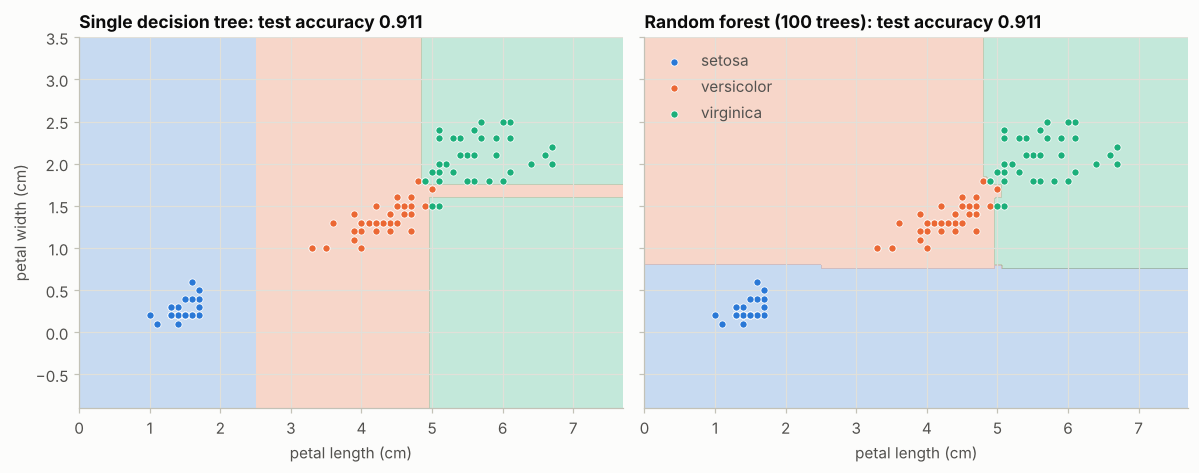

In [11]:
# EXTRA: (b) Decision regions of the single tree and the forest on the two petal features
import inspect
from matplotlib.colors import ListedColormap
from sklearn.inspection import DecisionBoundaryDisplay

if "multiclass_colors" in inspect.signature(DecisionBoundaryDisplay.from_estimator).parameters:
    region_colors = {"multiclass_colors": PALETTE}       # scikit-learn >= 1.7
else:
    region_colors = {"cmap": ListedColormap(PALETTE)}
petal = [2, 3]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True)
for ax, (title, model) in zip(axes, [("Single decision tree", DecisionTreeClassifier(random_state=2024)),
                                     ("Random forest (100 trees)", RandomForestClassifier(n_estimators=100, random_state=2024))]):
    model.fit(X_train[:, petal], y_train)
    DecisionBoundaryDisplay.from_estimator(model, X_train[:, petal], response_method="predict", ax=ax,
                                           alpha=0.25, grid_resolution=300, **region_colors)
    for k, color in enumerate(PALETTE):
        keep = y_train == k
        ax.scatter(X_train[keep, 2], X_train[keep, 3], s=22, color=color, edgecolor="white", lw=0.5,
                   label=iris.target_names[k])
    ax.set_title(f"{title}: test accuracy {model.score(X_test[:, petal], y_test):.3f}")
    ax.set_xlabel(iris.feature_names[2])
axes[0].set_ylabel(iris.feature_names[3])
axes[1].legend(loc="upper left")
plt.tight_layout()
plt.show()

**Output analysis.**

* **Accuracy 0.911, as in the book** (41 of 45), against 0.867 for the single tree. The forest corrects 2 of the tree's 6 errors and makes no new ones.
* **The importances** (Figure 8.4) rank petal length (0.45) and petal width (0.44) far ahead of the sepal features, as the book says.
* **(a) The forest versus its trees:**
  * the 100 trees score 0.901 on average, from 0.800 to 0.978, and their vote scores 0.911: averaging removes the luck of individual trees;
  * the **out-of-bag** accuracy, 0.962, is an honest estimate from the training set alone, and is closer to the cross-validation scores of recipe 1 than the noisy 45-flower test set.
* **Impurity versus permutation importance.** The two petal features share the impurity importance almost equally. When the test values are shuffled, the forest loses much more accuracy from **petal width** (0.45) than from petal length (0.22), while the sepal features cost nothing. The petal features are strongly correlated, and the impurity measure splits their credit; permutation shows which one the forest relies on.
* **(b) Decision regions.** On the two petal features both models score 0.911 on the test set, and both draw axis-aligned regions, because every tree splits on one feature at a time.
  * The single tree cuts setosa off with a vertical line at petal length 2.5. It adds a thin horizontal band near petal width 1.7, fitted to two training flowers.
  * The forest's vote averages many thresholds. It cuts setosa off below petal width 0.8 instead, and replaces the thin band with small steps along the versicolor/virginica border.
  * Away from the data the two models disagree completely: the top-left corner is setosa for the tree and versicolor for the forest. Trees extrapolate with whichever split happens to cover the empty space.

---
## 3. Gradient boosting machines

### Summary

* **Gradient boosting machines (GBMs)** build weak models, typically small trees, **sequentially**: each new tree tries to correct the errors of the previous ones, whereas a random forest builds its trees in parallel.
* **Getting ready** — the Iris data and the same split.
* **How to do it:**
  * Fit `GradientBoostingClassifier(n_estimators=1000, learning_rate=0.2, random_state=2024)` and show its classification report (Figure 8.5).
  * The results are "the same as our single decision tree model". The book suggests that both models may be overfitting and have reached a local maximum.
* **How it works** — each new tree models the **residuals** of the current model, starting from a simple initial prediction, so the error decreases step by step.
* **There's more:**
  * tune `learning_rate`, `max_depth` and `n_estimators`;
  * **early stopping** limits the iterative fitting to avoid overfitting;
  * **validation curves** compare training and validation scores as a hyperparameter changes.

### Theory: boosting as gradient descent in function space

**The additive model.** A GBM predicts with a sum of $M$ trees, built one at a time:

$$
F_M(x) = F_0(x) + \nu \sum_{m=1}^{M} h_m(x) ,
$$

where $F_0$ is a constant (the log-odds of the class frequencies) and $\nu$ is the **learning rate**.

**Each tree follows the negative gradient.** At stage $m$, every training sample gets a **pseudo-residual**, the negative gradient of the loss with respect to the current prediction:

$$
r_{im} = -\frac{\partial L\big(y_i, F(x_i)\big)}{\partial F(x_i)} \bigg|_{F = F_{m-1}} .
$$

A small regression tree $h_m$ is fitted to these residuals, and its leaf values are adjusted to the loss. For the squared error the pseudo-residuals are the ordinary residuals $y_i - F(x_i)$, which is the book's description. For classification the loss is the log-loss and the residuals are $y_i - p_i$ (true label minus predicted probability).

**Multiclass.** With $K$ classes, scikit-learn's `GradientBoostingClassifier` fits $K$ trees per stage, one per class, with a softmax across them. The book's model with 1,000 stages therefore contains 3,000 trees.

**Bias and variance.** Boosting starts from a very biased model and reduces bias stage by stage, using shallow trees (`max_depth=3` by default). Too many stages, or a large learning rate, eventually fit noise. The learning rate and the number of stages trade off: a smaller $\nu$ needs more trees but usually generalizes better (**shrinkage**).

**Early stopping.** `n_iter_no_change` with `validation_fraction` holds out part of the training data and stops adding trees when the validation loss stops improving. `HistGradientBoostingClassifier`, the fast histogram-based implementation (inspired by LightGBM), does this by default on large datasets.

In [12]:
# BOOK CODE: Gradient boosting machines -- getting ready (pp. 198-199)
# Load the libraries
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score

# Load the dataset
iris = load_iris()
X = iris.data
y = iris.target

# Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=2024)

In [13]:
# BOOK CODE: Gradient boosting machines -- how to do it (pp. 199-200)
# Instantiate the model
gbm_clf = GradientBoostingClassifier(
    n_estimators=1000,
    learning_rate=0.2,
    random_state=2024
)

# Fit the model to the training data
gbm_clf.fit(X_train, y_train)

# Generate predictions
y_pred = gbm_clf.predict(X_test)

# Evaluate the model
report = pd.DataFrame(classification_report(
    y_test, y_pred, output_dict=True)).transpose()

# Stylize the DataFrame
styled_df = (report
    .style
    .background_gradient(
        cmap='Blues',
        subset=['precision', 'recall', 'f1-score']
    )
    .format({
        'precision': '{:.3f}',
        'recall': '{:.3f}',
        'f1-score': '{:.3f}',
        'support': '{:.0f}'
    })
)
styled_df

,precision,recall,f1-score,support
0,1.000,1.000,1.000,18
1,0.714,0.833,0.769,12
2,0.846,0.733,0.786,15
accuracy,0.867,0.867,0.867,1
macro avg,0.853,0.856,0.852,45
weighted avg,0.873,0.867,0.867,45


stage                 : [1, 5, 10, 20, 50, 100, 500, 1000]
test accuracy         : [0.867, 0.867, 0.867, 0.889, 0.867, 0.867, 0.867, 0.867]
training loss (log)   : [0.7431, 0.2187, 0.0572, 0.0044, 0.0, 0.0, 0.0, 0.0]
trees in the model    : 3000 (1000 stages x 3 classes)
misclassifies exactly the same test flowers as the single tree: True


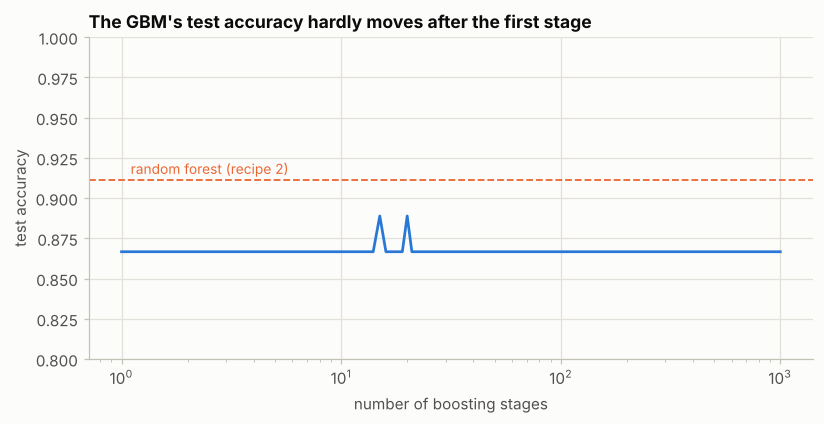

In [14]:
# EXTRA: (a) Test accuracy after every boosting stage, and the training loss
staged_accuracy = np.array([accuracy_score(y_test, stage_pred) for stage_pred in gbm_clf.staged_predict(X_test)])
stages = [1, 5, 10, 20, 50, 100, 500, 1000]
print("stage                 :", stages)
print("test accuracy         :", [round(float(staged_accuracy[s - 1]), 3) for s in stages])
print("training loss (log)   :", [round(float(gbm_clf.train_score_[s - 1]), 4) for s in stages])
print(f"trees in the model    : {gbm_clf.estimators_.size} ({gbm_clf.estimators_.shape[0]} stages x {gbm_clf.estimators_.shape[1]} classes)")
same = np.array_equal(gbm_clf.predict(X_test) != y_test, clf.predict(X_test) != y_test)
print(f"misclassifies exactly the same test flowers as the single tree: {same}")

fig, ax = plt.subplots(figsize=(8.5, 3.8))
ax.plot(np.arange(1, len(staged_accuracy) + 1), staged_accuracy, color=PALETTE[0], lw=1.8)
ax.axhline(accuracy_score(y_test, rf_clf.predict(X_test)), color=PALETTE[1], lw=1.2, ls="--")
ax.text(1.1, 0.913, "random forest (recipe 2)", color=PALETTE[1], va="bottom", fontsize=9)
ax.set_xscale("log")
ax.set_ylim(0.8, 1.0)
ax.set_xlabel("number of boosting stages")
ax.set_ylabel("test accuracy")
ax.set_title("The GBM's test accuracy hardly moves after the first stage")
plt.show()

In [15]:
# EXTRA: (b) Early stopping on a held-out 20% of the training data
early = GradientBoostingClassifier(n_estimators=1000, learning_rate=0.2, n_iter_no_change=10,
                                   validation_fraction=0.2, random_state=2024).fit(X_train, y_train)
print(f"stages kept by early stopping: {early.n_estimators_} of 1000; test accuracy {early.score(X_test, y_test):.3f}")

stages kept by early stopping: 44 of 1000; test accuracy 0.867


**Output analysis.**

* **Accuracy 0.867, the same as the single tree, as the book says.** The GBM's errors are not just as many as the tree's: they are exactly the same 6 test flowers.
* **(a) Overfitting is not the explanation:**
  * after **one** stage (three small trees) the test accuracy is already 0.867;
  * it touches 0.889 briefly between stages 15 and 20, then returns to 0.867 for the remaining 980 stages;
  * meanwhile the training loss falls to essentially zero by stage 100. The extra stages fit the training set ever more tightly without changing a single test prediction.

  The 6 flowers lie where versicolor and virginica overlap, and axis-aligned splits on these features put them on the wrong side, whether one tree or 3,000 make the cut. The forest (dashed line) averages trees grown on different bootstrap samples and feature subsets, which moves its thresholds enough to recover two of them.
* **(b) Early stopping** keeps 44 of the 1,000 stages, a model 23 times smaller, with the same test accuracy. The book's 1,000 stages at a learning rate of 0.2 are far more than this problem needs.

---
## 4. Hyperparameter tuning for trees and ensembles

### Summary

* Tuning hyperparameters such as the tree depth, the number of estimators and the learning rate optimizes trees and ensembles and prevents overfitting. The tools are the familiar grid search and cross-validation.
* **Getting ready** — the Iris data and the same split.
* **How to do it:**
  * Run `GridSearchCV` over a `GradientBoostingClassifier` with `n_estimators` in {50, 100, 150}, `max_depth` in {3, 4, 5} and `learning_rate` in {0.01, 0.1, 0.2} (5-fold, accuracy).
  * Print the best parameters, then show the classification report of the best model (Figure 8.6).
* **How it works:**
  * Grid search tests every combination and keeps the best cross-validation score.
  * The book describes `RandomizedSearchCV` as using "a randomized set of hyperparameters at the first iteration" and adjusting them "with each additional iteration".
* **Visualizing** — a seaborn heatmap of the mean CV accuracy by `max_depth` and `n_estimators` (Figure 8.7). The accuracy "does not improve" above a depth of 4 and 50 estimators.

### Theory: what the grid and the heatmap can tell

**Grid search** evaluates every combination of the grid with $k$-fold cross-validation and refits the best one on the whole training set (`best_estimator_`). When candidates **tie**, the first one in the grid's order wins. The grid's keys are sorted alphabetically, here `learning_rate`, then `max_depth`, then `n_estimators`.

**A pivot table averages.** `pivot_table(values='mean_test_score', index='param_max_depth', columns='param_n_estimators')` has three learning rates for every cell, and its default aggregation is the **mean**. So the heatmap shows the score averaged over the learning rates, not the score of any model that was actually fitted. To see the interaction, plot one heatmap per learning rate.

**Randomized search** (`RandomizedSearchCV`) is simpler than the book's description:

* it draws `n_iter` **independent** candidates from the given distributions (for example log-uniform for the learning rate) and cross-validates each;
* it does not adapt from one iteration to the next. That would be sequential model-based optimization (Bayesian optimization), which scikit-learn does not provide;
* its advantage is that the budget no longer depends on the size of the grid, and that continuous parameters get many distinct values instead of three.

**Successive halving** (`HalvingGridSearchCV`, `HalvingRandomSearchCV`) is the adaptive variant in scikit-learn: many candidates on a small budget, then the best fraction on a larger one.

**On a small, easy dataset** many settings reach the same score, and tuning cannot separate them. The choice then depends on tie-breaking, and the test score of the "best" model is as noisy as any single split.

In [16]:
# BOOK CODE: Hyperparameter tuning for trees and ensembles -- getting ready (p. 202)
# Load the libraries
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import (
    train_test_split, GridSearchCV)
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score

# Load the dataset
iris = load_iris()
X = iris.data
y = iris.target

# Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=2024)

In [17]:
# BOOK CODE: Hyperparameter tuning for trees and ensembles -- how to do it (pp. 203-204)
# Define the hyperparameter grid
param_grid = {
    'n_estimators': [50, 100, 150],
    'max_depth': [3, 4, 5],
    'learning_rate': [0.01, 0.1, 0.2]
}

# Set up GridSearchCV()
grid_search = GridSearchCV(
    GradientBoostingClassifier(random_state=2024),
    param_grid,
    cv=5,
    scoring='accuracy'
)

# Fit GridSearchCV() to the training data
grid_search.fit(X_train, y_train)

# Identify the best parameters
print(f'Best Parameters: {grid_search.best_params_}')

# Evaluate the best model
best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test)

# Generate the classification report
report = pd.DataFrame(classification_report(
    y_test, y_pred, output_dict=True)).transpose()

# Stylize the DataFrame
styled_df = (report
    .style
    .background_gradient(
        cmap='Blues',
        subset=['precision', 'recall', 'f1-score']
    )
    .format({
        'precision': '{:.3f}',
        'recall': '{:.3f}',
        'f1-score': '{:.3f}',
        'support': '{:.0f}'
    })
)
styled_df

Best Parameters: {'learning_rate': 0.01, 'max_depth': 4, 'n_estimators': 50}


,precision,recall,f1-score,support
0,1.000,1.000,1.000,18
1,0.714,0.833,0.769,12
2,0.846,0.733,0.786,15
accuracy,0.867,0.867,0.867,1
macro avg,0.853,0.856,0.852,45
weighted avg,0.873,0.867,0.867,45


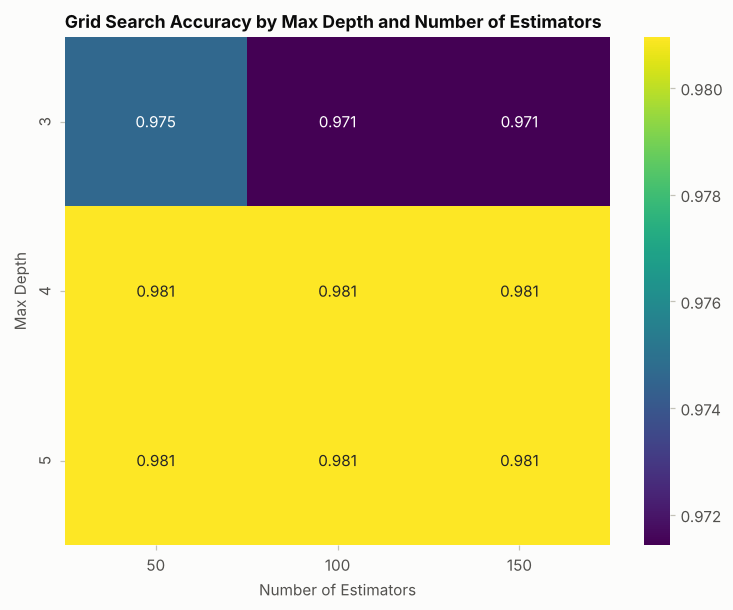

In [18]:
# BOOK CODE: Hyperparameter tuning for trees and ensembles -- visualizing the results (pp. 205-206)
# Load the libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Create a pivot table
results = pd.DataFrame(grid_search.cv_results_)
pivot_table = results.pivot_table(
    values='mean_test_score',
    index='param_max_depth',
    columns='param_n_estimators'
)

# Plot the heatmap
plt.figure(figsize=(8,6))
sns.heatmap(pivot_table, annot=True,
            fmt='.3f', cmap='viridis')
plt.title(
    'Grid Search Accuracy by Max Depth and Number of Estimators')
plt.xlabel('Number of Estimators')
plt.ylabel('Max Depth')
plt.show()

In [19]:
# EXTRA: (a) Ties, tie-breaking, and the scores hidden behind the heatmap's averages
best_cv = grid_search.best_score_
tied = results[results["rank_test_score"] == 1]
print(f"best mean CV accuracy {best_cv:.4f}, shared by {len(tied)} of {len(results)} candidates")
print(f"the winner is the first tied candidate in grid order: {grid_search.best_params_}")
print(f"its test accuracy: {accuracy_score(y_test, y_pred):.3f} (the untuned GBM of recipe 3 also scored 0.867)\n")
for rate in param_grid["learning_rate"]:
    table = results[results["param_learning_rate"] == rate].pivot_table(
        values="mean_test_score", index="param_max_depth", columns="param_n_estimators")
    print(f"learning_rate = {rate}:\n{table.round(3).to_string()}\n")

best mean CV accuracy 0.9810, shared by 20 of 27 candidates
the winner is the first tied candidate in grid order: {'learning_rate': 0.01, 'max_depth': 4, 'n_estimators': 50}
its test accuracy: 0.867 (the untuned GBM of recipe 3 also scored 0.867)

learning_rate = 0.01:
param_n_estimators    50     100    150
param_max_depth                        
3                   0.971  0.971  0.962
4                   0.981  0.981  0.981
5                   0.981  0.981  0.981

learning_rate = 0.1:
param_n_estimators    50     100    150
param_max_depth                        
3                   0.971  0.971  0.981
4                   0.981  0.981  0.981
5                   0.981  0.981  0.981

learning_rate = 0.2:
param_n_estimators    50     100    150
param_max_depth                        
3                   0.981  0.971  0.971
4                   0.981  0.981  0.981
5                   0.981  0.981  0.981



In [20]:
# EXTRA: (b) A randomized search: 20 independent candidates drawn from distributions
from scipy.stats import loguniform, randint
from sklearn.model_selection import RandomizedSearchCV

random_search = RandomizedSearchCV(
    GradientBoostingClassifier(random_state=2024),
    {"learning_rate": loguniform(0.005, 0.5), "max_depth": randint(1, 6), "n_estimators": randint(20, 300)},
    n_iter=20, cv=5, random_state=0)
random_search.fit(X_train, y_train)
best_random = {k: (round(float(v), 4) if isinstance(v, (float, np.floating)) else int(v)) for k, v in random_search.best_params_.items()}
print(f"best of 20 random candidates: {best_random}, CV accuracy {random_search.best_score_:.3f}, "
      f"test accuracy {random_search.score(X_test, y_test):.3f}")

best of 20 random candidates: {'learning_rate': 0.0979, 'max_depth': 5, 'n_estimators': 107}, CV accuracy 0.981, test accuracy 0.867


**Output analysis.**

* **The printed best parameters** are `{'learning_rate': 0.01, 'max_depth': 4, 'n_estimators': 50}`. The best model scores **0.867** on the test set, the same as the untuned GBM and the single tree.
* **(a) Why those parameters?**
  * **20 of the 27 candidates tie** at the best mean CV accuracy (0.981). The winner is simply the first tied candidate in the grid's alphabetical order: the smallest learning rate, then the smallest depth that ties, then the fewest trees.
  * The per-learning-rate tables show the same pattern for every rate. With `max_depth` 4 or 5 every combination reaches 0.981; only depth 3 sometimes scores a little lower.
  * The book's heatmap averages these three tables, so its cells are not scores of fitted models. Its reading (no gain above depth 4 and 50 estimators) is right, but for a simpler reason: on 105 flowers almost every setting fits as well as the data allow.
* **(b) The randomized search** draws 20 independent candidates, including learning rates and tree counts the grid never tries. It finds the same CV accuracy (0.981), with a learning rate near 0.1, depth 5 and 107 trees, and the same test accuracy (0.867). The limit is the data, not the search.

---
## 5. Comparing ensemble methods

### Summary

* Comparing ensembles reveals their strengths and weaknesses:
  * **bagging** reduces variance;
  * **boosting** reduces bias;
  * **stacking** combines different algorithms through a meta-model.
* **Getting ready** — the Iris data and the same split.
* **How to do it:**
  * Fit a random forest, a gradient boosting classifier (100 trees each), and a `StackingClassifier` that combines both with a `LogisticRegression` meta-model (`cv=5`).
  * Print the accuracies: random forest **0.91**, gradient boosting **0.87**, stacking **0.87**. "Our random forest model outperforms both GBM and the stacked model."
* **How it works** — the three ideas above, and a bar chart of the three accuracies (Figure 8.8).
* **There's more** — compare on more diverse datasets and with more metrics (precision, recall, F1, ROC).

### Theory: bagging, boosting and stacking side by side

| | Bagging / random forest | Boosting (GBM) | Stacking |
|---|---|---|---|
| How models are built | independently, on bootstrap samples (and random feature subsets) | sequentially, each on the errors of the current ensemble | different models, fitted independently |
| How they are combined | vote or average | weighted sum (learning rate) | a meta-model learns the combination |
| Typical base model | deep trees (low bias, high variance) | shallow trees (high bias, low variance) | any: trees, linear models, SVMs |
| Mainly reduces | variance | bias | both, if the base models make different errors |
| Parallel? | yes (`n_jobs`) | no (stages depend on each other) | base models yes |

**How stacking avoids leakage.** If the meta-model were trained on the base models' predictions for their own training data, it would learn to trust overfitted predictions. `StackingClassifier(cv=5)` therefore trains the meta-model on **out-of-fold** predictions: each training sample's base predictions come from models that did not see it. The base models are then refitted on all the data for prediction. By default the meta-model sees the predicted probabilities, `stack_method='auto'`, so with 2 base models and 3 classes it has 6 inputs.

**A fair comparison** needs the same folds for every model and several repetitions. On a 45-flower test set, a difference of two flowers is 4.4 percentage points: the size of the book's gap between the forest and the other two.

In [21]:
# BOOK CODE: Comparing ensemble methods -- getting ready (p. 207)
# Load the libraries
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.ensemble import (
    RandomForestClassifier, GradientBoostingClassifier)
from sklearn.ensemble import StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Load the dataset
iris = load_iris()
X = iris.data
y = iris.target

# Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=2024)

In [22]:
# BOOK CODE: Comparing ensemble methods -- how to do it (p. 208)
# Instantiate models
rf_clf = RandomForestClassifier(
    n_estimators=100, random_state=2024
)
gb_clf = GradientBoostingClassifier(
    n_estimators=100, random_state=2024
)
stacking_clf = StackingClassifier(
    estimators=[('rf', rf_clf), ('gb', gb_clf)],
    final_estimator=LogisticRegression(),
    cv=5
)

# Fit the models
rf_clf.fit(X_train, y_train)
gb_clf.fit(X_train, y_train)
stacking_clf.fit(X_train, y_train)

# Generate predictions
rf_pred = rf_clf.predict(X_test)
gb_pred = gb_clf.predict(X_test)
stacking_pred = stacking_clf.predict(X_test)

# Evaluate the models
rf_accuracy = accuracy_score(y_test, rf_pred)
gb_accuracy = accuracy_score(y_test, gb_pred)
stacking_accuracy = accuracy_score(y_test, stacking_pred)

# Print the accuracy scores
print(f'Random Forest Accuracy: {rf_accuracy:.2f}')
print(f'Gradient Boosting Accuracy: {gb_accuracy:.2f}')
print(f'Stacking Accuracy: {stacking_accuracy:.2f}')

Random Forest Accuracy: 0.91
Gradient Boosting Accuracy: 0.87
Stacking Accuracy: 0.87


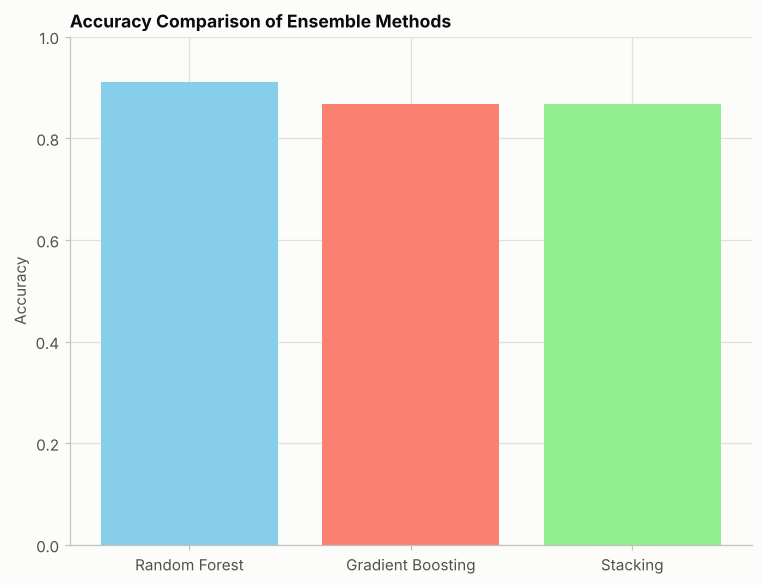

In [23]:
# BOOK CODE: Comparing ensemble methods -- how it works: bar plot (p. 209)
# Load the libraries
import matplotlib.pyplot as plt

# Create a bar plot
methods = [
    'Random Forest', 'Gradient Boosting', 'Stacking'
]
accuracies = [
    rf_accuracy, gb_accuracy, stacking_accuracy
]

# Plot the bar plot
plt.figure(figsize=(8, 6))
plt.bar(methods, accuracies, color=['skyblue',
        'salmon', 'lightgreen'])
plt.title('Accuracy Comparison of Ensemble Methods')
plt.ylabel('Accuracy')
plt.ylim(0, 1)
plt.show()

In [24]:
# EXTRA: (a) Inside the stacking model -- what the meta-model learned
print(f"meta-model inputs: {stacking_clf.final_estimator_.n_features_in_} "
      f"(2 base models x 3 class probabilities)")
coef = pd.DataFrame(stacking_clf.final_estimator_.coef_.round(2), index=iris.target_names,
                    columns=[f"{m} P({c})" for m in ["rf", "gb"] for c in iris.target_names])
print(coef.to_string())
print(f"\nstacking predictions identical to gradient boosting's: {np.array_equal(stacking_pred, gb_pred)}")

meta-model inputs: 6 (2 base models x 3 class probabilities)
            rf P(setosa)  rf P(versicolor)  rf P(virginica)  gb P(setosa)  gb P(versicolor)  gb P(virginica)
setosa              1.36             -0.66            -0.70          1.38             -0.64            -0.74
versicolor         -0.72              1.09            -0.37         -0.74              1.25            -0.51
virginica          -0.64             -0.43             1.07         -0.64             -0.60             1.25

stacking predictions identical to gradient boosting's: True


In [25]:
# EXTRA: (b) Seven tree methods on three datasets, with the same repeated 5-fold cross-validation
from sklearn.datasets import load_wine, load_breast_cancer
from sklearn.ensemble import BaggingClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score
from sklearn.tree import DecisionTreeClassifier

datasets = {"iris": load_iris(return_X_y=True), "wine": load_wine(return_X_y=True),
            "breast cancer": load_breast_cancer(return_X_y=True)}
models = {
    "decision tree": DecisionTreeClassifier(random_state=0),
    "bagging (100 trees)": BaggingClassifier(DecisionTreeClassifier(), n_estimators=100, random_state=0),
    "random forest": RandomForestClassifier(n_estimators=100, random_state=0),
    "extra trees": ExtraTreesClassifier(n_estimators=100, random_state=0),
    "gradient boosting": GradientBoostingClassifier(n_estimators=100, random_state=0),
    "hist gradient boosting": HistGradientBoostingClassifier(random_state=0),
    "stacking (RF + GB)": StackingClassifier(
        [("rf", RandomForestClassifier(n_estimators=100, random_state=0)),
         ("gb", GradientBoostingClassifier(n_estimators=100, random_state=0))],
        final_estimator=LogisticRegression(max_iter=1000), cv=5),
}
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=0)
comparison = pd.DataFrame({name: {data_name: cross_val_score(model, Xd, yd, cv=cv).mean()
                                  for data_name, (Xd, yd) in datasets.items()}
                           for name, model in models.items()}).T.round(3)
print("mean accuracy over 10 folds (5-fold CV repeated twice):")
print(comparison.to_string())

mean accuracy over 10 folds (5-fold CV repeated twice):
                         iris   wine  breast cancer
decision tree           0.947  0.919          0.927
bagging (100 trees)     0.947  0.961          0.956
random forest           0.950  0.978          0.962
extra trees             0.953  0.986          0.967
gradient boosting       0.943  0.947          0.963
hist gradient boosting  0.950  0.977          0.968
stacking (RF + GB)      0.947  0.966          0.966


**Output analysis.**

* **The printed accuracies reproduce the book exactly:** random forest 0.91, gradient boosting 0.87, stacking 0.87. The bar chart (Figure 8.8) shows the same three numbers.
* **(a) Stacking:**
  * The meta-model has 6 inputs (2 models x 3 class probabilities), and its coefficients give both base models similar weights for each class.
  * Its test predictions coincide with gradient boosting's: on these 45 flowers, adding the forest changed nothing.
  * Stacking only helps when the base models make *different* errors, and on Iris all tree models fail on the same overlapping flowers.
* **(b) On three datasets with ten folds each, the picture changes:**
  * On **Iris** all seven methods score between 0.943 and 0.953, so the book's ranking from a single split is noise.
  * On **Wine** (13 features) the ensembles clearly beat the single tree (0.919): random forest 0.978, extra trees **0.986**, histogram gradient boosting 0.977. Plain bagging (0.961) is below the forest, which shows the value of the random feature subsets. Classic gradient boosting is weakest among the ensembles here (0.947).
  * On **Breast Cancer** (30 features) every ensemble scores between 0.956 and 0.968, against 0.927 for one tree.
  * **Stacking** is never the best. With `cv=5` it fits each base model six times (five cross-validation fits and a final one), without beating the best of them.

The robust lesson is the one the book's *How it works* gives: averaging many decorrelated trees (forests, extra trees) is a strong default. Which ensemble wins depends on the dataset, and on small datasets the differences are within the cross-validation noise.

---
## 6. Practical exercises with tree-based models

### Summary

The chapter ends with three exercises (pp. 211–212), each a list of steps; the official solutions in the book's repository choose the datasets:

1. **Building and evaluating a decision tree classifier** — on the **Wine** dataset (178 wines, 13 chemical features, 3 cultivars).
2. **Hyperparameter tuning with random forests** — a grid search over `n_estimators`, `max_depth` and `max_features` on the **Breast Cancer** data.
3. **Comparing gradient boosting and random forest** — on the **Digits** dataset (1,797 images of 8 by 8 pixels, 10 classes).

The official notebook stores no outputs; the solutions are run as published.

### Theory: what the exercises show

* **Exercise 1** fits a single, fully grown tree. On Wine the features have different scales, which does not matter for trees: a split is a threshold on one feature, so any monotone rescaling gives the same tree. Trees need no `StandardScaler`.
* **Exercise 2** tunes a forest. Two parameters control the *strength* of each tree (`max_depth`) and the *diversity* between trees (`max_features`: $\sqrt{30} \approx 5$ or $\log_2 30 \approx 4$ features per split). More trees never hurt a forest's accuracy; they only cost time.
* **Exercise 3** compares the two families on 10 classes. `GradientBoostingClassifier` fits **one tree per class per stage**, so 100 stages mean 1,000 trees fitted one after another, while the forest fits 100 trees that can run in parallel. That is why the GBM is much slower here. `HistGradientBoostingClassifier` bins the features into histograms and is far faster on such data.

In [26]:
# BOOK CODE: Exercise 1 -- building and evaluating a decision tree classifier (official solution)
# Load libraries
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report

# Load the dataset
wine = load_wine()
X = wine.data
y = wine.target

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

# Create and train the classifier
clf = DecisionTreeClassifier(random_state=2024)
clf.fit(X_train, y_train)

# Make predictions
y_pred = clf.predict(X_test)

#Evaluate performance
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      0.78      0.88        18
           1       0.79      0.95      0.86        20
           2       0.94      0.94      0.94        16

    accuracy                           0.89        54
   macro avg       0.91      0.89      0.89        54
weighted avg       0.90      0.89      0.89        54



In [27]:
# BOOK CODE: Exercise 2 -- hyperparameter tuning with random forests (official solution)
# Load libraries
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# Load the dataset
cancer = load_breast_cancer()
X = cancer.data
y = cancer.target

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

# Define hyperparameter grid and perform grid search
param_grid = {
    'n_estimators': [50, 100, 150],
    'max_depth': [3, 5, 7],
    'max_features': ['sqrt', 'log2']
}
grid_search = GridSearchCV(RandomForestClassifier(random_state=2024), param_grid, cv=5, error_score='raise')
grid_search.fit(X_train, y_train)

# Evaluate the best model
best_rf = grid_search.best_estimator_
y_pred = best_rf.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print(f'Best Parameters: {grid_search.best_params_}')
print(f'Accuracy: {accuracy:.2f}')

Best Parameters: {'max_depth': 5, 'max_features': 'sqrt', 'n_estimators': 150}
Accuracy: 0.95


In [28]:
# BOOK CODE: Exercise 3 -- comparing gradient boosting and random forest (official solution)
# Load libraries
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score

# Load the dataset
digits = load_digits()
X = digits.data
y = digits.target

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

# Create and train models
rf_clf = RandomForestClassifier(n_estimators=100, random_state=2024)
gb_clf = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, random_state=2024)
rf_clf.fit(X_train, y_train)
gb_clf.fit(X_train, y_train)

# Make predictions and evaluate
rf_pred = rf_clf.predict(X_test)
gb_pred = gb_clf.predict(X_test)
rf_accuracy = accuracy_score(y_test, rf_pred)
gb_accuracy = accuracy_score(y_test, gb_pred)
print(f'Random Forest Accuracy: {rf_accuracy:.2f}')
print(f'Gradient Boosting Accuracy: {gb_accuracy:.2f}')

Random Forest Accuracy: 0.97
Gradient Boosting Accuracy: 0.96


**Output analysis.**

* **Exercise 1:** the single tree classifies **0.89** of the 54 test wines correctly. It is uneven: cultivar 0 has perfect precision but a recall of 0.78, and four of its 18 wines go to other classes.
* **Exercise 2:**
  * The grid search selects `{'max_depth': 5, 'max_features': 'sqrt', 'n_estimators': 150}`, with a test accuracy of **0.95**.
  * Two of the 18 candidates tie at the best CV accuracy (0.955), so here too the order of the grid decides between them.
  * The unscaled features do not matter for a forest.
* **Exercise 3:** on Digits the random forest scores **0.97** and gradient boosting **0.96**. They are close, but the GBM needs about twenty times longer to fit (extra (b) shows why).

In [29]:
# EXTRA: (a) Exercise 1 with a random forest -- the same data, the same split
wine_forest = RandomForestClassifier(n_estimators=100, random_state=2024)
Xw_train, Xw_test, yw_train, yw_test = train_test_split(wine.data, wine.target, test_size=0.3, random_state=2024)
wine_forest.fit(Xw_train, yw_train)
wine_tree = DecisionTreeClassifier(random_state=2024).fit(Xw_train, yw_train)
print(f"Wine test accuracy: single tree {wine_tree.score(Xw_test, yw_test):.3f}, random forest {wine_forest.score(Xw_test, yw_test):.3f}")

Wine test accuracy: single tree 0.889, random forest 0.944


In [30]:
# EXTRA: (b) Exercise 3 -- how many trees each model fits, and a histogram-based GBM
import time
from sklearn.ensemble import HistGradientBoostingClassifier

print(f"random forest trees     : {len(rf_clf.estimators_)}")
print(f"gradient boosting trees : {gb_clf.estimators_.size} ({gb_clf.estimators_.shape[0]} stages x {gb_clf.estimators_.shape[1]} classes)")
start = time.perf_counter()
hist_gb = HistGradientBoostingClassifier(random_state=2024).fit(X_train, y_train)
print(f"HistGradientBoostingClassifier: test accuracy {hist_gb.score(X_test, y_test):.3f}, "
      f"fitted in {time.perf_counter() - start:.1f} s")

random forest trees     : 100
gradient boosting trees : 1000 (100 stages x 10 classes)
HistGradientBoostingClassifier: test accuracy 0.967, fitted in 1.8 s


**Output analysis.**

* **(a)** On the exercise 1 split, a random forest classifies **0.944** of the wines correctly against 0.889 for the single tree: three more wines, the variance reduction of recipe 2 at work. Recipe 5's cross-validation (0.978 against 0.919) confirms the gap.
* **(b)** The forest fits 100 trees; gradient boosting fits **1,000** (100 stages times 10 classes), sequentially, which explains the time difference. `HistGradientBoostingClassifier` reaches a similar accuracy (0.967) in a fraction of the time. It is the gradient boosting implementation to prefer on anything but tiny datasets.

---
## Decision guide: choosing a tree-based model

| Situation | Choice | Notes |
|---|---|---|
| An interpretable model, rules to show to people | `DecisionTreeClassifier(max_depth=...)` | limit the depth or use `ccp_alpha`; expect instability |
| A strong default with little tuning | `RandomForestClassifier` (or `ExtraTreesClassifier`) | more trees never hurt; tune `max_features` and leaf size |
| The best accuracy on tabular data, especially with many samples | `HistGradientBoostingClassifier` | built-in early stopping, missing values and categorical features |
| A small dataset, careful tuning | `GradientBoostingClassifier` with early stopping (`n_iter_no_change`) | tune the learning rate and the number of stages together |
| Models with different strengths (trees, linear, kernel) | `StackingClassifier` | only helps if the base models make different errors; costs `cv` times more |
| Which features matter | `permutation_importance` on held-out data | impurity importances split credit among correlated features |
| A free validation estimate for a forest | `oob_score=True` | uses the out-of-bag samples of each tree |
| Feature scaling | not needed | splits are thresholds on one feature at a time |

## Chapter summary and key takeaways

| Recipe | Main tools | Key idea |
|---|---|---|
| Decision trees | `DecisionTreeClassifier`, `plot_tree` | Greedy splits that maximize the impurity decrease; deep trees memorize the training set |
| Random forests and bagging | `RandomForestClassifier`, `BaggingClassifier`, `oob_score` | Averaging bootstrap trees with random feature subsets reduces variance |
| Gradient boosting | `GradientBoostingClassifier`, `staged_predict`, early stopping | Shallow trees added sequentially along the negative gradient of the loss reduce bias |
| Hyperparameter tuning | `GridSearchCV`, `RandomizedSearchCV` | On easy data many settings tie; pivot tables average; random search samples independently |
| Comparing ensembles | `StackingClassifier`, `RepeatedStratifiedKFold` | Compare on the same folds, repeatedly, on several datasets |
| Practical exercises | Wine, Breast Cancer, Digits | Trees need no scaling; multiclass GBMs fit one tree per class per stage |

**Key takeaways**

1. A decision tree is a sequence of greedy, axis-aligned splits that reduce impurity. Grown to the end, it fits the training set perfectly. Limit its depth or prune it, and expect a different tree after a small change in the data.
2. Random forests average many deep trees grown on bootstrap samples with random feature subsets. They reduce variance, need little tuning, and give a free out-of-bag estimate.
3. Gradient boosting adds shallow trees that follow the gradient of the loss. Use early stopping or validation curves rather than a fixed, large number of stages, and prefer `HistGradientBoostingClassifier` for speed.
4. Feature importances need care: impurity-based importances are computed on training data and split credit between correlated features; permutation importance on held-out data shows what the model uses.
5. Rankings from one small test set are noise. Compare models with repeated cross-validation on the same folds, and on more than one dataset.

**Book (scikit-learn 1.5) vs. the version used here — notes from the reproduction**

* All listings and the three official exercise solutions run unchanged on scikit-learn 1.9.1, and every printed result reproduces: 0.867 for the tree, 0.911 for the forest, the GBM equal to the tree, and 0.91 / 0.87 / 0.87 in the comparison.
* The random forest, GBM and tuning listings use `classification_report` without importing it (it comes from recipe 1). The notebook runs them in order, as the book does.
* In the listing's `plot_tree` call (without `proportion=True`), "samples" and "value" are counts, while the text describes proportions; the official notebook adds `proportion=True`, `rounded=True` and `fontsize=10`.
* Precisions to the chapter text:
  * Gini impurity reaches at most $1 - 1/K$ (0.667 for three classes), not 1.0.
  * The GBM's equality with the single tree is not caused by overfitting: its test accuracy is already 0.867 after the first stage, and both models miss the same six flowers.
  * The tuning heatmap averages each cell over the three learning rates.
  * `RandomizedSearchCV` draws independent candidates; it does not adjust them from one iteration to the next.
  * The forest's advantage over boosting and stacking on Iris is two flowers; over repeated cross-validation all methods tie on Iris.

## References

1. Sukup, J. (2025). *scikit-learn Cookbook* (3rd ed.). Packt Publishing. Code repository: <https://github.com/PacktPublishing/scikit-learn-Cookbook-Third-Edition>
2. Breiman, L., Friedman, J. H., Olshen, R. A., & Stone, C. J. (1984). *Classification and Regression Trees*. Wadsworth.
3. Breiman, L. (1996). Bagging predictors. *Machine Learning, 24*(2), 123–140.
4. Breiman, L. (2001). Random forests. *Machine Learning, 45*(1), 5–32.
5. Geurts, P., Ernst, D., & Wehenkel, L. (2006). Extremely randomized trees. *Machine Learning, 63*(1), 3–42.
6. Friedman, J. H. (2001). Greedy function approximation: a gradient boosting machine. *The Annals of Statistics, 29*(5), 1189–1232.
7. Ke, G., Meng, Q., Finley, T., Wang, T., Chen, W., Ma, W., Ye, Q., & Liu, T.-Y. (2017). LightGBM: a highly efficient gradient boosting decision tree. *Advances in Neural Information Processing Systems, 30*.
8. Wolpert, D. H. (1992). Stacked generalization. *Neural Networks, 5*(2), 241–259.
9. Strobl, C., Boulesteix, A.-L., Zeileis, A., & Hothorn, T. (2007). Bias in random forest variable importance measures. *BMC Bioinformatics, 8*, 25.
10. Bergstra, J., & Bengio, Y. (2012). Random search for hyper-parameter optimization. *Journal of Machine Learning Research, 13*, 281–305.
11. Hastie, T., Tibshirani, R., & Friedman, J. (2009). *The Elements of Statistical Learning* (2nd ed.). Springer.
12. scikit-learn documentation: [Decision trees](https://scikit-learn.org/stable/modules/tree.html) · [Ensembles](https://scikit-learn.org/stable/modules/ensemble.html) · [Permutation importance](https://scikit-learn.org/stable/modules/permutation_importance.html) · [Tuning the hyper-parameters of an estimator](https://scikit-learn.org/stable/modules/grid_search.html)